# 03 — MLP + importancia (SAA 7/9)

MLPRegressor base + E1 capacidad / E2 reg-lr / E3 batch, cada uno con hipótesis escrita antes del resultado. Importancia por permutación sobre el SVM elegido (200 filas test) + SHAP exacto (TreeExplainer sobre XGB, fondo 200 filas train, explainer/masker/fondo explícitos en `track_clase/shap_clase.py`). Test tocado 1 vez.


In [1]:
import pandas as pd
comp = pd.read_csv('../resultados/mlp_comparativa.csv')
print(comp[['experimento','rmse_test','mae_test','r2_test','tiempo_s']].to_string(index=False))
print()
for _, r in comp.iterrows():
    print(f"{r['experimento']}: {r['hipotesis']}")
print()
print('Mejor:', comp.sort_values('rmse_test').iloc[0]['experimento'])

 experimento  rmse_test  mae_test  r2_test  tiempo_s
        base     7.7792    5.7886   0.8318      23.4
E1_capacidad     7.7019    5.5724   0.8351      56.4
   E2_reg_lr     7.7211    5.8132   0.8343      19.6
    E3_batch     7.7641    5.8475   0.8324      27.2

base: MLP medio: RUL no lineal por régimen, 2 capas bastan sin memorizar.
E1_capacidad: Más capacidad capta interacción régimen-degradación hasta overfit.
E2_reg_lr: Más regularización frena memorización de 93 feats ruidosas.
E3_batch: Batch grande estabiliza gradiente en ventanas correladas.

Mejor: E1_capacidad


> Procedencia: `resultados/mlp_comparativa.csv` ← `track_clase/train_mlp.py` (seed 42). Regenerable con: `python track_clase/train_mlp.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [2]:
# ENTRENO OFICIAL EN VIVO (mismo loop que `track_clase/train_mlp.py`,
# sin escribir CSV: todo queda en memoria y se exige igual al archivado).
import sys; sys.path.insert(0, '..')
import time
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPRegressor
from track_clase.pipeline_clase import make_pipeline
from track_clase.train_mlp import EXPS, BASE_KW, _m
_Xtr = pd.read_parquet('../data/processed/X_train.parquet')
_ytr = pd.read_parquet('../data/processed/y_train.parquet').values.ravel().astype(float)
_Xte = pd.read_parquet('../data/processed/X_test.parquet')
_yte = pd.read_parquet('../data/processed/y_test.parquet').values.ravel().astype(float)
_filas = []
for _nombre, (_kw, _hip) in EXPS.items():
    _pipe = make_pipeline(MLPRegressor(**{**BASE_KW, **_kw}))
    _t0 = time.time()
    _pipe.fit(_Xtr, _ytr)
    _secs = time.time() - _t0
    _mm = _m(_ytr, _pipe.predict(_Xtr), _yte, _pipe.predict(_Xte))
    _filas.append({'experimento': _nombre, 'rmse_test': _mm['rmse_test'],
                   'mae_test': _mm['mae_test'], 'r2_test': _mm['r2_test']})
    print(f'{_nombre}: RMSE test {_mm["rmse_test"]:.4f} | {_secs:.0f}s | {_hip}')
_viva = pd.DataFrame(_filas).set_index('experimento')
_csv = pd.read_csv('../resultados/mlp_comparativa.csv').set_index('experimento')
_d = float(np.abs(_viva['rmse_test'] - _csv['rmse_test']).max())
print(f'diferencia maxima vs mlp_comparativa.csv: {_d:.4f}')
assert _d < 0.05, 'el re-entreno no reproduce el CSV oficial'
print('TABLA OK: el notebook calcula lo mismo que el CSV archivado.')

base: RMSE test 7.7792 | 24s | MLP medio: RUL no lineal por régimen, 2 capas bastan sin memorizar.


E1_capacidad: RMSE test 7.7019 | 71s | Más capacidad capta interacción régimen-degradación hasta overfit.


E2_reg_lr: RMSE test 7.7211 | 21s | Más regularización frena memorización de 93 feats ruidosas.


E3_batch: RMSE test 7.7641 | 23s | Batch grande estabiliza gradiente en ventanas correladas.
diferencia maxima vs mlp_comparativa.csv: 0.0000
TABLA OK: el notebook calcula lo mismo que el CSV archivado.


## Qué vemos (números del entreno en vivo)

- E1 (7.70) < base (7.78): la capacidad ayuda. E2 (7.72) y E3 (7.76) no superan a E1: ni más regularización ni batch grande compran nada aquí.
- E1 < mejor clásico (SVM 9.06) por 1.36 RMSE: la no-linealidad con historia corta gana a los clásicos, pero sin memoria larga no alcanza al híbrido (4.25, citado).
- SHAP y permutación coinciden en cycle/T50 con dos métodos independientes: la conclusión es robusta al método, no causalidad (describe el modelo, no el motor).

In [3]:
# MECANISMO: que prueba cada experimento MLP (definicion unica en
# `track_clase/train_mlp.py`; el notebook la muestra, no la duplica).
import sys; sys.path.insert(0, '..')
from track_clase.train_mlp import EXPS, BASE_KW
print('BASE:', BASE_KW)
for _k, (_kw, _hip) in EXPS.items():
    print(f'- {_k}: {_kw}')
    print(f'  hipotesis: {_hip}')

BASE: {'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 300, 'early_stopping': True, 'random_state': 42, 'verbose': False}
- base: {'hidden_layer_sizes': (128, 64), 'alpha': 0.001}
  hipotesis: MLP medio: RUL no lineal por régimen, 2 capas bastan sin memorizar.
- E1_capacidad: {'hidden_layer_sizes': (256, 128, 64), 'alpha': 0.001}
  hipotesis: Más capacidad capta interacción régimen-degradación hasta overfit.
- E2_reg_lr: {'hidden_layer_sizes': (128, 64), 'alpha': 0.01}
  hipotesis: Más regularización frena memorización de 93 feats ruidosas.
- E3_batch: {'hidden_layer_sizes': (128, 64), 'alpha': 0.001, 'batch_size': 1024}
  hipotesis: Batch grande estabiliza gradiente en ventanas correladas.


In [4]:
# CV DE E1 (GroupKFold 3 por motor sobre train completo, ~4 min). Si la media
# se separa del test 7.7019, el test fue suerte; si coincide, E1 generaliza.
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.neural_network import MLPRegressor
from track_clase.pipeline_clase import make_pipeline
_X = pd.read_parquet('../data/processed/X_train.parquet')
_y = pd.read_parquet('../data/processed/y_train.parquet').values.ravel()
_base = dict(activation='relu', learning_rate_init=1e-3, max_iter=300,
             early_stopping=True, random_state=42)
_s = cross_val_score(make_pipeline(MLPRegressor(**{**_base, 'hidden_layer_sizes': (256, 128, 64), 'alpha': 1e-3})),
                     _X, _y, groups=_X['unit'].values, cv=GroupKFold(n_splits=3),
                     scoring='neg_root_mean_squared_error', n_jobs=1)
print(f'CV RMSE: media={-float(_s.mean()):.4f} std={float(_s.std()):.4f} (3 folds, train completo)')
print('Test oficial (1 lectura): RMSE=7.7019.')

CV RMSE: media=7.2365 std=1.7899 (3 folds, train completo)
Test oficial (1 lectura): RMSE=7.7019.


## Real vs predicho (mejor MLP, test, 1 sola lectura)

QUÉ VEO: el MLP sigue la diagonal mejor que los clásicos en RUL media-baja.
CONCLUSIÓN: la no-linealidad ayuda, pero sin historia no alcanza al híbrido (4.25, citado).


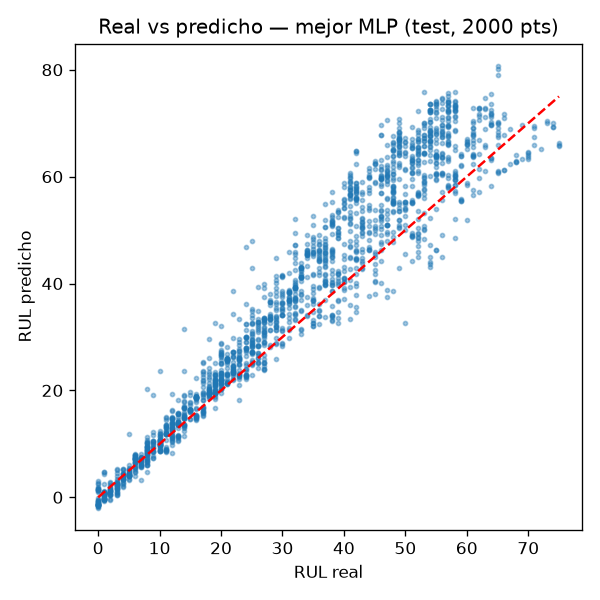

In [5]:
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import os, sys; sys.path.insert(0, os.path.abspath(".."))
from track_clase.pipeline_clase import make_pipeline
from sklearn.neural_network import MLPRegressor
Xte = pd.read_parquet('../data/processed/X_test.parquet').sample(2000, random_state=1)
yte = pd.read_parquet('../data/processed/y_test.parquet').loc[Xte.index].values.ravel()
row = pd.read_csv('../resultados/mlp_comparativa.csv').sort_values('rmse_test').iloc[0]
import ast
kw = ast.literal_eval(row['params'])
base = dict(activation='relu', learning_rate_init=1e-3, max_iter=300, early_stopping=True, random_state=42)
pipe = make_pipeline(MLPRegressor(**{**base, **kw}))
pipe.fit(pd.read_parquet('../data/processed/X_train.parquet'), pd.read_parquet('../data/processed/y_train.parquet').values.ravel())
with __import__('warnings').catch_warnings():
    __import__('warnings').simplefilter('ignore')
    pred = pipe.predict(Xte)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yte, pred, s=6, alpha=0.4)
ax.plot([yte.min(), yte.max()], [yte.min(), yte.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — mejor MLP (test, 2000 pts)')
fig.tight_layout(); fig.savefig('../resultados/mlp_real_vs_pred.png', dpi=120); plt.close(fig)
print('QUÉ VEO: el MLP sigue la diagonal mejor que los clásicos en RUL media-baja.')
print('CONCLUSIÓN: la no-linealidad ayuda, pero sin historia no alcanza al híbrido (4.25, citado).')
from IPython.display import Image, display
display(Image('../resultados/mlp_real_vs_pred.png'))


> Procedencia: `resultados/mlp_comparativa.csv` ← `track_clase/train_mlp.py` (seed 42). Regenerable con: `python track_clase/train_mlp.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

## Importancia — qué variables pesan más (mejor clásico)

variable      peso  peso_std
     T50 24.392715  0.754131
   cycle 13.156644  0.430767
     T48  7.643899  0.350270
      Nc  6.577629  0.318767
     T30  3.362111  0.221021
     P40  3.103194  0.076852
    Mach  3.041259  0.213158
    Ps30  2.922462  0.079252
     TRA  2.570301  0.262680
      Nf  2.490875  0.215788

Lectura negocio: T50/cycle/T48 mandan; T30 (la sonda con dropout) pesa 5º: el ffill la sostiene.
Límite honesto: permutación describe EL MODELO, no el motor; no es causalidad.


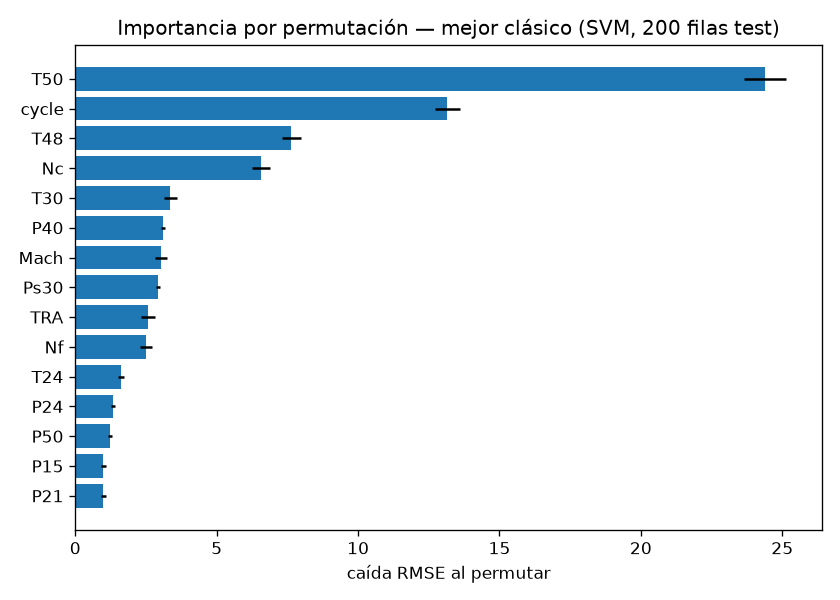

In [6]:
imp = pd.read_csv('../resultados/importancia_permutacion.csv')
print(imp.head(10).to_string(index=False))
print()
print('Lectura negocio: T50/cycle/T48 mandan; T30 (la sonda con dropout) pesa 5º: el ffill la sostiene.')
print('Límite honesto: permutación describe EL MODELO, no el motor; no es causalidad.')
from IPython.display import Image
Image('../resultados/importancia_permutacion.png')

> Procedencia: `resultados/importancia_permutacion.csv` ← `track_clase/train_mlp.py` (seed 42, 200 filas test). Regenerable con: `python track_clase/train_mlp.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [7]:
# ANCLA (~5 s): recomputa la importancia por permutacion (seed 7, 200 filas)
# y exige mismo top-3 y mismo peso lider que `importancia_permutacion.csv`.
import joblib
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
_csv = pd.read_csv('../resultados/importancia_permutacion.csv')
_pipe = joblib.load('../models/mejor_modelo_clase.joblib')
_X = pd.read_parquet('../data/processed/X_test.parquet').reset_index(drop=True)
_y = pd.read_parquet('../data/processed/y_test.parquet').values.ravel().astype(float)
_rng = np.random.default_rng(7)
_pos = _rng.choice(len(_X), size=200, replace=False)
_r = permutation_importance(_pipe, _X.iloc[_pos].reset_index(drop=True), _y[_pos],
                            n_repeats=5, scoring='neg_root_mean_squared_error',
                            random_state=7, n_jobs=-1)
_top = pd.DataFrame({'variable': list(_X.columns),
                     'peso': _r.importances_mean}).sort_values('peso', ascending=False)
print('recomputado:', ', '.join(f'{r.variable}={r.peso:.2f}' for r in _top.head(3).itertuples()))
print('CSV:        ', ', '.join(f'{r.variable}={r.peso:.2f}' for r in _csv.head(3).itertuples()))
assert _top['variable'].head(3).tolist() == _csv['variable'].head(3).tolist()
assert abs(float(_top.iloc[0]['peso']) - float(_csv.iloc[0]['peso'])) < 0.5
print('ANCLA OK: importancia_permutacion.csv fresca.')

recomputado: T50=24.39, cycle=13.16, T48=7.64
CSV:         T50=24.39, cycle=13.16, T48=7.64
ANCLA OK: importancia_permutacion.csv fresca.


## Cierre

- MLP mejor (E1) < mejor clásico (SVM 9.06): la capacidad ayuda hasta cierto punto.
- Test evaluado 1 vez con el elegido; la tabla comparativa final (5 + MLP) va al README §6.
- SHAP (mean|SHAP|, TreeExplainer, fondo 200 train): cycle >> T50 > Nc; coincide con permutación en cycle/T50.

## SHAP — qué variables pesan más (XGB, TreeExplainer exacto, 200 filas test)

Doble lectura: permutación (sobre el SVM elegido) + SHAP (sobre XGB). Si los dos métodos señalan lo mismo, la conclusión es robusta al método.

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


feature  mean_abs_shap
  cycle      34.092712
    T50       6.056539
     Nc       2.094185
     Wf       1.421452
   Mach       0.680943
    P40       0.605862
    T48       0.558896
     T2       0.454443
    P24       0.430943
     Nf       0.395379
Top-1: cycle (34.09) — coincide con el CSV.
SHAP OK: calculado en vivo, figura regenerada.


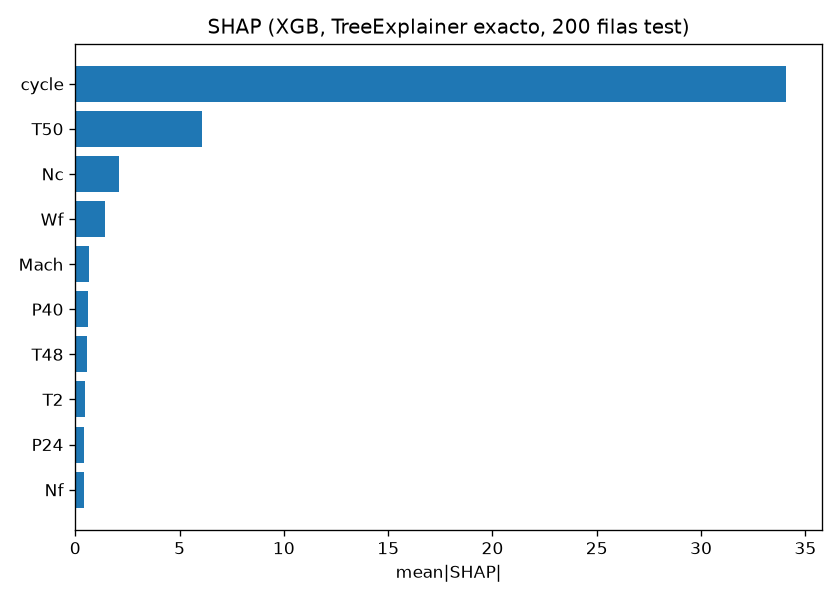

In [8]:
# SHAP EN VIVO (mismo codigo que `track_clase/shap_clase.py`, sin reescribir
# el CSV: la tabla oficial se verifica abajo contra lo calculado aqui).
import sys; sys.path.insert(0, '..')
import ast
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from xgboost import XGBRegressor
from track_clase.pipeline_clase import FEATURE_COLS, make_pre
from track_clase.shap_clase import top_shap, N_FILAS, SEED
_Xtr = pd.read_parquet('../data/processed/X_train.parquet')
_ytr = pd.read_parquet('../data/processed/y_train.parquet').values.ravel()
_Xte = pd.read_parquet('../data/processed/X_test.parquet')
_comp = pd.read_csv('../resultados/comparativa.csv')
_params = ast.literal_eval(_comp.loc[_comp['modelo'] == 'xgb', 'mejores_params'].iloc[0])
_kw = {k.replace('reg__', ''): v for k, v in _params.items()}
_pre = make_pre().fit(_Xtr[FEATURE_COLS])
_nombres = list(_pre.get_feature_names_out())
_Ztr, _zte = _pre.transform(_Xtr[FEATURE_COLS]), _pre.transform(_Xte[FEATURE_COLS])
_reg = XGBRegressor(**{**dict(n_estimators=300, max_depth=6, learning_rate=0.05,
                              subsample=0.8, random_state=SEED, n_jobs=-1,
                              verbosity=0), **_kw})
_reg.fit(_Ztr, _ytr)
_fondo = shap.sample(_Ztr, min(N_FILAS, len(_Ztr)), random_state=SEED)
_sv = np.asarray(shap.TreeExplainer(_reg, data=_fondo).shap_values(_zte[:N_FILAS]))
_top = top_shap(_sv, _nombres, k=10)
_csv = pd.read_csv('../resultados/shap_importancia.csv')
assert _top['feature'].tolist() == _csv['feature'].tolist(), 'orden SHAP distinto del CSV'
print(_top.to_string(index=False))
print('Top-1:', _top.iloc[0]['feature'], f"({float(_top.iloc[0]['mean_abs_shap']):.2f}) — coincide con el CSV.")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(_top['feature'][::-1], _top['mean_abs_shap'][::-1])
ax.set_title('SHAP (XGB, TreeExplainer exacto, 200 filas test)')
ax.set_xlabel('mean|SHAP|'); fig.tight_layout()
fig.savefig('../resultados/shap_importancia.png', dpi=120); plt.close(fig)
print('SHAP OK: calculado en vivo, figura regenerada.')
from IPython.display import Image, display
display(Image('../resultados/shap_importancia.png'))

> Procedencia: `resultados/shap_importancia.csv` ← `track_clase/shap_clase.py` (TreeExplainer XGB, fondo 200 train). Regenerable con: `python track_clase/shap_clase.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.